# EM rate vs. IF-score removal target

Loads `em_rates/*.json` (one row per cluster run, written by `em_influence.rates misaligned`) and plots the misaligned rate against the target % of total positive IF score removed, split by which token pool (first completion token vs. everything else) the removal was drawn from.

In [1]:
import glob

import pandas as pd

em_rates_dir = "/Users/tarn/Desktop/Work/SPAR2026/Codes/EMinf/em_rates"
paths = sorted(glob.glob(f"{em_rates_dir}/*.json"))
print(f"{len(paths)} files")
df = pd.concat([pd.read_csv(p) for p in paths], ignore_index=True)
df

5 files


,dataset,model,source,method,subset,seed,answers,misaligned_pct
0,career,olmo,NaN,unfiltered,full,0,880,47.272727
1,career,olmo,olmo,tokens-ekfac-firstpos,remove_top_0.115424,0,880,48.295455
2,career,olmo,olmo,tokens-ekfac-firstpos,remove_top_0.218136,0,880,48.409091
3,career,olmo,olmo,tokens-ekfac-otherpos,remove_top_0.001050,0,880,46.022727
4,career,olmo,olmo,tokens-ekfac-otherpos,remove_top_0.001533,0,880,43.181818


In [2]:
# The `subset` string (e.g. "remove_top_0.218136") encodes the *pool fraction*
# removed (count / len(pool)), not the target % of total positive IF score we
# actually asked selection.extreme() for -- that target was fixed when the
# subset was chosen (top 1/2/3/4%, see tokenIFscores.ipynb's exact_subset_fraction
# table), so map it back explicitly here rather than re-deriving it, which
# would mean reloading the full token_scores.npz pools just for 4 numbers.
TARGET_PCT = {
    ("tokens-ekfac-firstpos", "remove_top_0.115424"): 3,
    ("tokens-ekfac-firstpos", "remove_top_0.218136"): 4,
    ("tokens-ekfac-otherpos", "remove_top_0.001050"): 3,
    ("tokens-ekfac-otherpos", "remove_top_0.001533"): 4,
}
POOL_LABEL = {
    "tokens-ekfac-firstpos": "firstpos",
    "tokens-ekfac-otherpos": "otherpos",
    "unfiltered": "baseline",
}

df["pool"] = df["method"].map(POOL_LABEL)
df["target_pct"] = [TARGET_PCT.get((m, s), 0) for m, s in zip(df["method"], df["subset"])]
df = df.sort_values(["pool", "target_pct"]).reset_index(drop=True)
df[["pool", "method", "subset", "target_pct", "answers", "misaligned_pct"]]

,pool,method,subset,target_pct,answers,misaligned_pct
0,baseline,unfiltered,full,0,880,47.272727
1,firstpos,tokens-ekfac-firstpos,remove_top_0.115424,3,880,48.295455
2,firstpos,tokens-ekfac-firstpos,remove_top_0.218136,4,880,48.409091
3,otherpos,tokens-ekfac-otherpos,remove_top_0.001050,3,880,46.022727
4,otherpos,tokens-ekfac-otherpos,remove_top_0.001533,4,880,43.181818


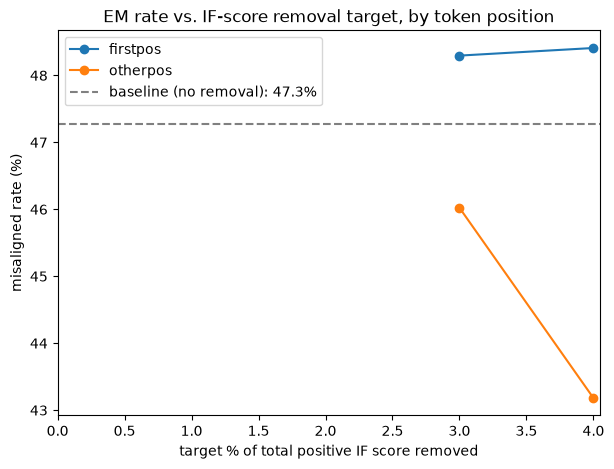

In [3]:
import matplotlib.pyplot as plt

baseline_rate = df.loc[df["pool"] == "baseline", "misaligned_pct"].iloc[0]

fig, ax = plt.subplots(figsize=(7, 5))
for pool, color in [("firstpos", "tab:blue"), ("otherpos", "tab:orange")]:
    sub = df[df["pool"] == pool].sort_values("target_pct")
    ax.plot(sub["target_pct"], sub["misaligned_pct"], "o-", color=color, label=pool)

ax.axhline(baseline_rate, color="gray", linestyle="--",
           label=f"baseline (no removal): {baseline_rate:.1f}%")
ax.set_xlabel("target % of total positive IF score removed")
ax.set_ylabel("misaligned rate (%)")
ax.set_title("EM rate vs. IF-score removal target, by token position")
ax.legend()
ax.set_xlim(left=0)
plt.show()